# Predictive Detection of Network Intrusions Using Machine Learning
### NSL-KDD Dataset | Network Intrusion Detection System (NIDS)

**Objective:** Build and compare machine-learning classifiers that classify network connections as Normal, DoS, Probe, R2L, or U2R.

**Workflow:** Data understanding → preprocessing → model training → evaluation → interpretation.

> **Dataset setup:** Download the NSL-KDD files from the supplied Kaggle page. Place `KDDTrain+.txt` and `KDDTest+.txt` in the same folder as this notebook. If your downloaded files have different names, update the paths in the next cell.

## 1. Import libraries and Setup Environment

Before writing any machine learning code, we need to import Python libraries that provide specialized tools for handling data, creating visualizations, and building models. Here is a breakdown of what we are setting up:
* **`warnings`**: Network datasets can trigger minor warnings (such as deprecation notices from older functions). We suppress these to keep our output clean.
* **`numpy` & `pandas`**: These are the foundational tools for data science. Pandas lets us store and manipulate data in tabular structures called DataFrames (similar to Excel sheets), while Numpy handles fast mathematical operations on arrays.
* **`matplotlib` & `seaborn`**: These libraries are used to design and render visual plots, graphs, and charts to help us understand our data patterns.
* **`sklearn` (Scikit-Learn)**: This is the primary library for traditional machine learning in Python. We import preprocessing utilities (scaling numerical data, converting text categories to numbers) and models (Random Forest, Support Vector Machines).
* **`seaborn.set_theme`**: This configures the visual styling of our plots to use a clean grid and a cohesive color palette.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils.class_weight import compute_sample_weight

sns.set_theme(style="whitegrid", palette="viridis")
RANDOM_STATE = 42

## 2. Load the NSL-KDD dataset

The **NSL-KDD dataset** is a famous benchmark dataset used to train and test Network Intrusion Detection Systems (NIDS). Each row in this dataset represents a network connection, described by 41 distinct features (such as connection duration, protocol type, bytes sent, error rates, etc.).

Additionally, each row contains:
1. A **`label`** indicating whether the connection was normal or specified as a specific type of cyber attack.
2. A **`difficulty`** score (which we won't need for training our classifiers, so we will drop it later).

In the code cell below, we explicitly define the names of these 43 columns (41 features + label + difficulty) and load the training and testing datasets from text files into Pandas DataFrames.

In [ ]:
# Change these paths if your downloaded files are stored elsewhere
TRAIN_PATH = "KDDTrain+.txt"
TEST_PATH = "KDDTest+.txt"

columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins",
    "logged_in", "num_compromised", "root_shell", "su_attempted",
    "num_root", "num_file_creations", "num_shells", "num_access_files",
    "num_outbound_cmds", "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate",
    "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"
]

train_df = pd.read_csv(TRAIN_PATH, names=columns)
test_df = pd.read_csv(TEST_PATH, names=columns)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)
display(train_df.head())

Training shape: (125973, 43)
Testing shape: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


## 3. Data Understanding & Exploratory Analysis

Once data is loaded, we must inspect it to understand its structure. We check:
* **`info()`**: Tells us how many entries we have, the data type of each column (numerical vs. text), and whether there are empty (null) cells.
* **Missing Values**: Machine learning algorithms usually fail if there are missing values. We verify if any exist.
* **Duplicate Rows**: Duplicates can artificially skew our model's performance, so we check for them.
* **Attack Labels**: There are many distinct individual attack names in the dataset (e.g., 'neptune', 'satan', 'smurf'). We output the frequency of these labels to see how common each type of connection is.

In [ ]:
print("Training data information:")
train_df.info()
print("\nMissing values:", train_df.isnull().sum().sum())
print("\nDuplicate rows:", train_df.duplicated().sum())
print("\nNumber of unique attack labels:", train_df["label"].nunique())
print(train_df["label"].value_counts().head(15))

Training data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  object 
 2   service                      125973 non-null  object 
 3   flag                         125973 non-null  object 
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-null  int64  
 11  logged_in                    125973 non-null  int64  
 12  num_compromised              12

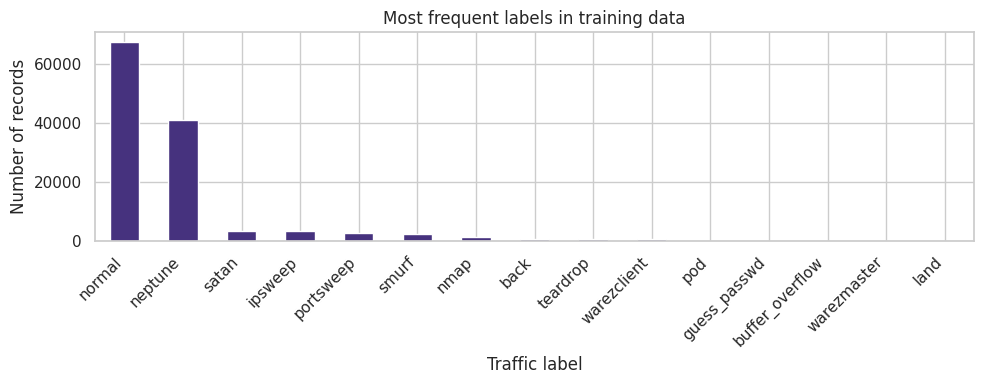

In [ ]:
plt.figure(figsize=(10, 4))
train_df["label"].value_counts().head(15).plot(kind="bar")
plt.title("Most frequent labels in training data")
plt.xlabel("Traffic label")
plt.ylabel("Number of records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 4. Classifying Attacks into Core Categories

Instead of predicting dozens of individual, highly specific attack names, network security standards group them into **four major attack families** based on their behavior:
1. **DoS (Denial of Service)**: Attacks designed to overwhelm system resources, making services unavailable to legitimate users (e.g., Neptune, Smurf).
2. **Probe**: Surveillance attacks where an intruder scans a network to gather information or find vulnerabilities (e.g., Portsweep, Satan).
3. **R2L (Remote to Local)**: Unauthorized access attacks where an attacker attempts to gain local user access from a remote machine (e.g., guessing passwords).
4. **U2R (User to Root)**: Privilege escalation attacks where an attacker starts with standard user access and exploits a vulnerability to gain root/administrator access.

We define lists containing the individual attacks for each family and use a helper function `group_attack` to map each specific label into one of these 4 families, or leave it as `Normal` if there is no threat.

In [ ]:
dos_attacks = {
    "back", "land", "neptune", "pod", "smurf", "teardrop",
    "mailbomb", "apache2", "udpstorm", "processtable", "worm"
}
probe_attacks = {
    "ipsweep", "nmap", "portsweep", "satan", "mscan", " saint"
}
r2l_attacks = {
    "ftp_write", "guess_passwd", "imap", "multihop", "phf",
    "spy", "warezclient", "warezmaster", "sendmail", " named",
    "snmpgetattack", "snmpguess", "xlock", "xsnoop", "worm"
}
u2r_attacks = {
    "buffer_overflow", "loadmodule", "perl", "rootkit",
    "ps", "sqlattack", "xterm"
}

def group_attack(label):
    name = str(label).strip().lower().rstrip(".")
    if name == "normal":
        return "Normal"
    if name in dos_attacks:
        return "DoS"
    if name in probe_attacks:
        return "Probe"
    if name in r2l_attacks:
        return "R2L"
    if name in u2r_attacks:
        return "U2R"
    return "Other"

train_df["target"] = train_df["label"].apply(group_attack)
test_df["target"] = test_df["label"].apply(group_attack)

print("Training grouped labels:")
print(train_df["target"].value_counts())
print("\nUnmapped labels:")
print(sorted(set(train_df.loc[train_df.target == "Other", "label"].unique())))

Training grouped labels:
target
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Unmapped labels:
[]


### Preparing Features and Targets for Machine Learning

Before feeding data into our models, we separate our inputs (features) from our desired outputs (targets):
* **`X` (Features)**: The 41 network characteristics. We drop the columns `label` (original specific attack text), `difficulty` (irrelevant metadata), and `target` (the class we want to predict).
* **`y` (Target)**: The target variable we want the model to learn to predict (`target` column containing the 5 grouped categories).

In [ ]:
train_df = train_df[train_df["target"] != "Other"].copy()
test_df = test_df[test_df["target"] != "Other"].copy()

# Remove the original text label and difficulty field; keep the 41 traffic features
X_train = train_df.drop(columns=["label", "difficulty", "target"])
y_train = train_df["target"]
X_test = test_df.drop(columns=["label", "difficulty", "target"])
y_test = test_df["target"]

print("Classes:", sorted(y_train.unique()))
print("Train:", X_train.shape, " Test:", X_test.shape)

Classes: ['DoS', 'Normal', 'Probe', 'R2L', 'U2R']
Train: (125973, 41)  Test: (22075, 41)


## 5. Feature Preprocessing Pipeline

Machine learning algorithms require numeric inputs. However, our dataset contains three categorical (text-based) features: `protocol_type` (e.g., TCP, UDP), `service` (e.g., HTTP, FTP), and `flag` (status of the connection).

To handle this, we construct a **Preprocessing Pipeline**:
1. **One-Hot Encoding**: Converts categorical text columns into multiple binary (0 or 1) columns. For example, if a protocol is 'TCP', it creates a 'protocol_type_tcp' column with a value of 1, and 'protocol_type_udp' with 0.
2. **Standard Scaling**: Numerical values in our dataset vary wildly (e.g., source bytes can be in millions, while error rates are between 0 and 1). Algorithms like SVM perform poorly when scales differ so much. We scale numerical values so they have a mean of 0 and a variance of 1.

We package these instructions into a `ColumnTransformer` to automate preprocessing consistently.

In [ ]:
categorical_cols = ["protocol_type", "service", "flag"]
numeric_cols = [c for c in X_train.columns if c not in categorical_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", StandardScaler(), numeric_cols)
    ]
)

## 6. Managing Severe Class Imbalance

If we look at our class distribution, normal connections and DoS attacks dominate the dataset, while U2R and R2L attacks are extremely rare. If we train our model on this raw data, the model might learn to completely ignore the rare attacks because it can still achieve high overall accuracy just by guessing 'Normal' or 'DoS'.

To combat this, we compute **class-balanced sample weights**. This technique penalizes the model more heavily when it makes a mistake on rare classes (like U2R), forcing it to pay closer attention to them during training.

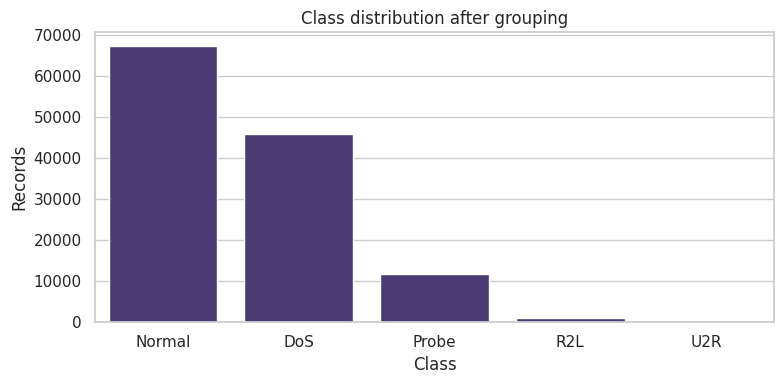

In [ ]:
plt.figure(figsize=(8, 4))
sns.countplot(data=train_df, x="target", order=["Normal", "DoS", "Probe", "R2L", "U2R"])
plt.title("Class distribution after grouping")
plt.xlabel("Class")
plt.ylabel("Records")
plt.tight_layout()
plt.show()

sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

## 7. Model Definitions

We select three distinct, powerful classification algorithms to compare:
1. **Random Forest**: An ensemble model that builds many independent decision trees and merges their predictions to get a more accurate and stable forecast.
2. **Support Vector Machine (SVM)**: A model that finds the optimal boundary line (hyperplane) that maximizes the separation between different classes in a high-dimensional space.
3. **XGBoost (Extreme Gradient Boosting)**: A state-of-the-art decision-tree boosting algorithm that trains trees sequentially, where each new tree focuses on correcting the errors made by the previous ones.

In [ ]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=150, random_state=RANDOM_STATE,
        class_weight="balanced_subsample", n_jobs=-1
    ),
    "SVM": SVC(
        kernel="rbf", C=1.0, class_weight="balanced"
    )
}

# Optional XGBoost
try:
    from xgboost import XGBClassifier
    label_encoder = LabelEncoder()
    y_train_encoded = label_encoder.fit_transform(y_train)
    xgb_model = XGBClassifier(
        n_estimators=150, max_depth=6, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8,
        objective="multi:softprob", eval_metric="mlogloss",
        random_state=RANDOM_STATE, n_jobs=-1
    )
    models["XGBoost"] = xgb_model
    print("XGBoost is available.")
except ImportError:
    print("XGBoost not installed; Random Forest and SVM will run.")

XGBoost is available.


In [ ]:
trained_models = {}
predictions = {}
results = []

for name, model in models.items():
    print("Training:", name)
    if name == "XGBoost":
        Xtr = preprocessor.fit_transform(X_train)
        Xte = preprocessor.transform(X_test)
        model.fit(Xtr, y_train_encoded, sample_weight=sample_weights)
        pred_encoded = model.predict(Xte)
        pred = label_encoder.inverse_transform(pred_encoded.astype(int))
    else:
        pipe = Pipeline([("preprocess", preprocessor), ("model", model)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        model = pipe

    trained_models[name] = model
    predictions[name] = pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score (macro)", ascending=False)
display(results_df.round(4))

Training: Random Forest
Training: SVM
Training: XGBoost


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
2,XGBoost,0.7903,0.8069,0.5669,0.5973
1,SVM,0.7646,0.6961,0.5521,0.5403
0,Random Forest,0.7394,0.7552,0.4620,0.4682


## 8. Detailed Evaluation Metrics

When dealing with imbalanced datasets, **Accuracy** (the percentage of total correct predictions) is highly misleading. We must use more robust metrics:
* **Precision**: Out of all connections the model predicted as a specific attack, how many were actually that attack? (High precision means low false alarm rates).
* **Recall (Sensitivity)**: Out of all actual attacks of a specific category, how many did our model successfully catch? (High recall means low missed attacks).
* **F1-Score**: The harmonic mean of Precision and Recall, giving us a single balanced score representing overall quality.
* **Macro Averaging**: We calculate metrics for each of the 5 classes individually and take their unweighted average. This ensures rare classes (like U2R) are weighted equally to common classes (like Normal) in our final comparison.

In [ ]:
for name, pred in predictions.items():
    print("\n", "=" * 60)
    print(name)
    print(classification_report(y_test, pred, labels=["Normal", "DoS", "Probe", "R2L", "U2R"], zero_division=0))


Random Forest
              precision    recall  f1-score   support

      Normal       0.64      0.97      0.77      9711
         DoS       0.96      0.77      0.85      7460
       Probe       0.83      0.53      0.65      2102
         R2L       0.85      0.00      0.01      2735
         U2R       0.50      0.03      0.06        67

    accuracy                           0.74     22075
   macro avg       0.76      0.46      0.47     22075
weighted avg       0.79      0.74      0.69     22075


SVM
              precision    recall  f1-score   support

      Normal       0.68      0.97      0.80      9711
         DoS       0.96      0.77      0.85      7460
       Probe       0.82      0.66      0.73      2102
         R2L       0.96      0.13      0.23      2735
         U2R       0.06      0.24      0.09        67

    accuracy                           0.76     22075
   macro avg       0.70      0.55      0.54     22075
weighted avg       0.82      0.76      0.74     22075


X

## 9. Analyzing Confusion Matrices

A **Confusion Matrix** is a table layout that lets us visualize the performance of an algorithm. Each row represents instances in an actual class, while each column represents instances in a predicted class.

By looking at the diagonal boxes (from top-left to bottom-right), we can see exactly how many connections were classified correctly. Off-diagonal numbers show us exactly where the model got confused (for example, misclassifying R2L attacks as Normal).

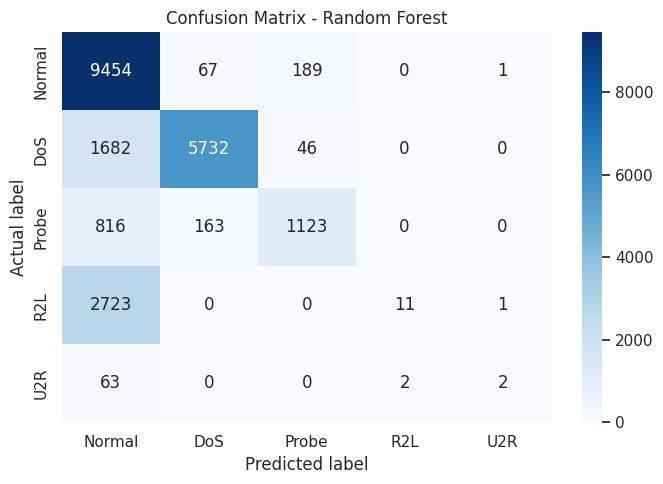

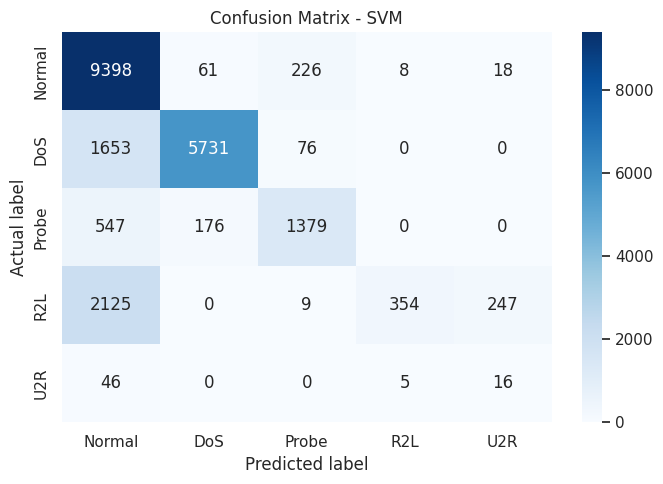

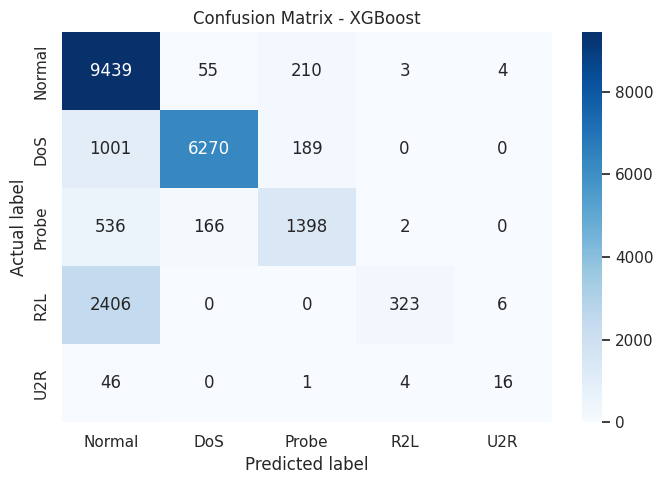

In [ ]:
for name, pred in predictions.items():
    cm = confusion_matrix(y_test, pred, labels=["Normal", "DoS", "Probe", "R2L", "U2R"])
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Normal", "DoS", "Probe", "R2L", "U2R"],
                yticklabels=["Normal", "DoS", "Probe", "R2L", "U2R"], ax=ax)
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    plt.tight_layout()
    plt.show()

## 10. Performance Comparison Visualizations

To make our decision-making process intuitive, we compile the accuracy, macro precision, macro recall, and macro F1-score from all three models into a single bar chart. This visual comparison lets us easily see which algorithm handled the challenges of multi-class classification and class imbalance best.

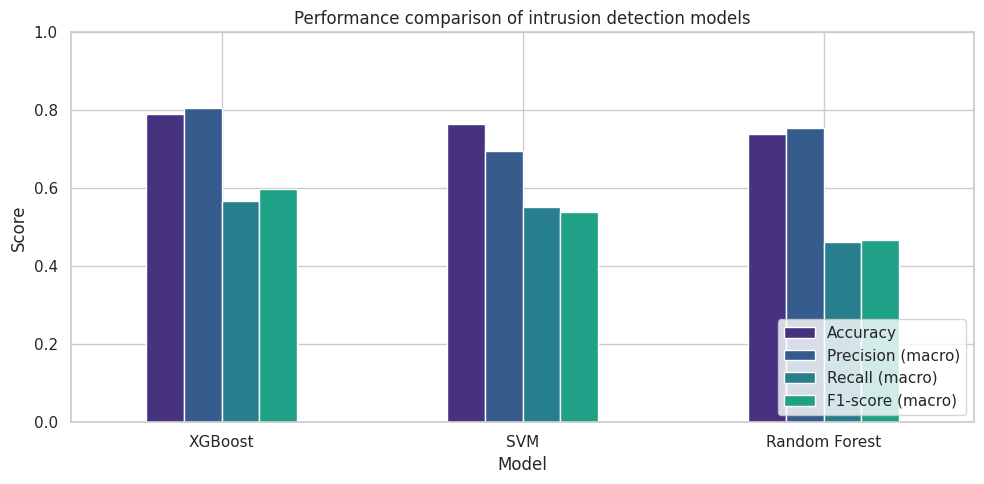

In [ ]:
metrics = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
plot_df = results_df.set_index("Model")[metrics]
ax = plot_df.plot(kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0)
ax.set_title("Performance comparison of intrusion detection models")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 11. Explaining the Model: Feature Importance

Machine learning shouldn't be a "black box". We want to understand *why* our models make their decisions. For the Random Forest classifier, we can extract **Feature Importances**, which measure how much each network feature contributed to reducing uncertainty when classifying traffic.

We plot the top 15 features to find out which aspects of network communication (such as the number of bytes sent or the count of connections to the same host) are the strongest indicators of malicious activity.

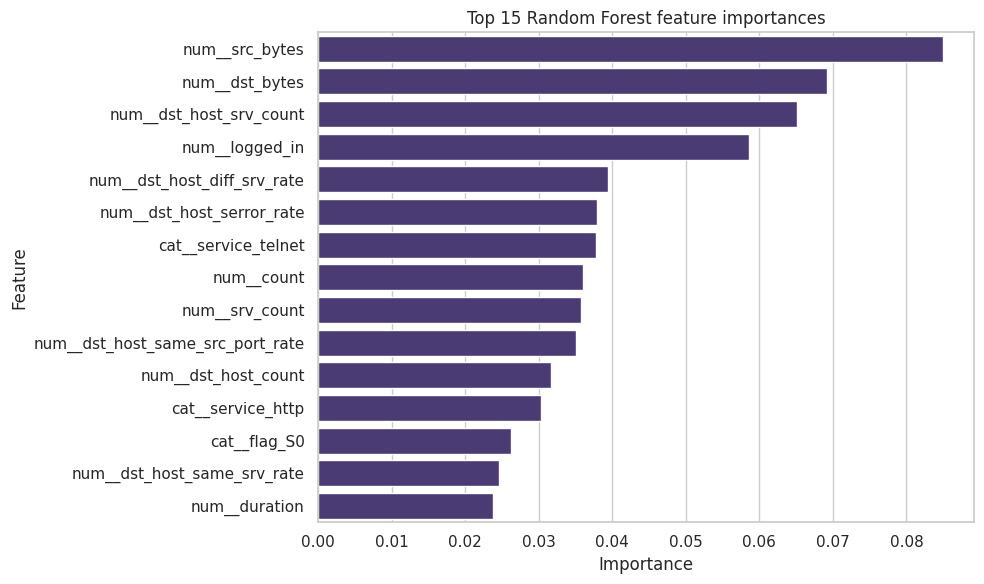

,Feature,Importance
85,num__src_bytes,0.084930
86,num__dst_bytes,0.069184
113,num__dst_host_srv_count,0.065131
92,num__logged_in,0.058575
115,num__dst_host_diff_srv_rate,0.039410
118,num__dst_host_serror_rate,0.037867
63,cat__service_telnet,0.037852
103,num__count,0.036087
104,num__srv_count,0.035698
116,num__dst_host_same_src_port_rate,0.035062


In [ ]:
if "Random Forest" in trained_models:
    rf_pipe = trained_models["Random Forest"]
    prep = rf_pipe.named_steps["preprocess"]
    rf = rf_pipe.named_steps["model"]

    feature_names = prep.get_feature_names_out()
    importances = rf.feature_importances_
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False).head(15)

    plt.figure(figsize=(10, 6))
    sns.barplot(data=importance_df, x="Importance", y="Feature")
    plt.title("Top 15 Random Forest feature importances")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
    display(importance_df)

## 12. Real-Time Prediction Demonstration

To show how this system would work in a real-world scenario, we pull a single connection log from our test set, feed its raw features into our trained Random Forest pipeline, and look at the output. This shows how quickly and directly a trained model can evaluate live network traffic.

In [ ]:
if "Random Forest" in trained_models:
    sample = X_test.iloc[[0]]
    actual = y_test.iloc[0]
    predicted = trained_models["Random Forest"].predict(sample)[0]
    print("Actual class:", actual)
    print("Predicted class:", predicted)

Actual class: DoS
Predicted class: DoS


## 13. Conclusion

This notebook implements a multi-class network intrusion detection workflow using the NSL-KDD dataset. It preprocesses network features, trains Random Forest, SVM, and (when installed) XGBoost, and evaluates them using accuracy, macro precision, macro recall, macro F1-score, classification reports, and confusion matrices.

**Complete this section after running the notebook:** Report the measured scores from the comparison table, describe which attack categories were most often misclassified, and discuss the top features found by Random Forest. Do not claim a model is best until you have examined the actual results.

**Limitations:** NSL-KDD is a benchmark dataset and may not represent current real-world network traffic. High test performance does not by itself establish readiness for deployment. A production NIDS would require validation on contemporary traffic, monitoring for data drift, and careful false-positive analysis.